In [1]:
import torch
from torchvision import datasets
from torch import nn
from torch.utils.data import DataLoader
from torchvision.transforms import v2

In [2]:
from datasets import load_dataset
ds = load_dataset("timm/eurosat-rgb")   # DatasetDict: train / validation / test
train = ds["train"]

In [3]:
ds

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 16200
    })
    validation: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 5400
    })
    test: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 5400
    })
})

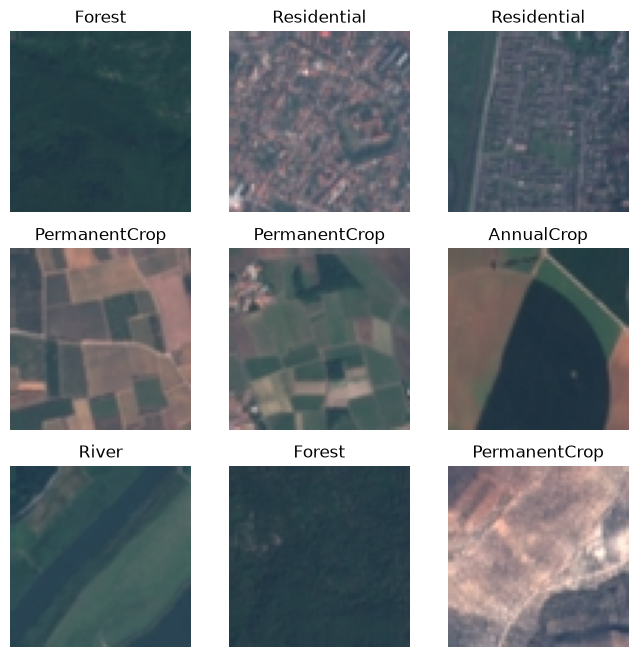

In [4]:
#visualization
import matplotlib.pyplot as plt
import random
labels_map = {
    0: "AnnualCrop",
    1: "Forest",
    2: "HerbaceousVegatation",
    3: "Highway",
    4: "Industrial",
    5: "Pasture",
    6: "PermanentCrop",
    7: "Residential",
    8: "River",
    9: "SeaLaket",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols*rows+1):
    sample_idx = random.randint(0,len(train)-1)    
    img, label = train['image'][sample_idx], train['label'][sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img)
plt.show()

In [5]:
from torch.utils.data import Dataset
class CustomDataset(Dataset):
    def __init__(self, Ds, transform):
        self.img_labels = Ds
        self.transform = transform
        
    def __len__(self):
        return len(self.img_labels)
    def __getitem__(self, idx):
        sample = self.img_labels[idx]
        image, label = sample['image'], sample['label']
        if self.transform:
            image = self.transform(image)
        return image, label

In [6]:
transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
train_set = CustomDataset(ds["train"], transform) 
val_set = CustomDataset(ds["validation"], transform)
test_set = CustomDataset(ds["test"], transform)

In [7]:
#loading the Dataset into the Dataloaders
train_dataloader = DataLoader(train_set, batch_size=32, shuffle=True)
val_dataloader = DataLoader(test_set, batch_size=32, shuffle=False)

Feature batch shape: torch.Size([32, 3, 64, 64])
Labels batch shape: torch.Size([32])


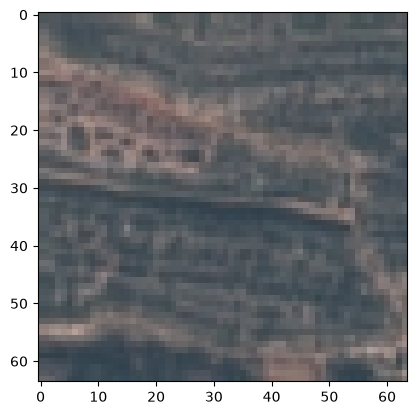

Label: 2


In [8]:
train_features, train_labels,  = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].permute(1, 2, 0)
label = train_labels[0]
plt.imshow(img)
plt.show()
print(f"Label: {label}")

In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [10]:
device

'cpu'

In [11]:
#simple cnn network
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn_relu_stack=nn.Sequential(
            nn.Conv2d(3,32,3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32,64,3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64,128,3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(128,128),
            nn.ReLU(),
            nn.Linear(128,10)
        )
    def forward(self, x):
        logits = self.cnn_relu_stack(x)
        return logits
        

In [12]:
#Image to Patches
class ImgtoPatchEmbds(nn.Module):
    def __init__(self, img_size=64, patch_size=16, embed_size=192):
        super().__init__()
        num_patches = (img_size//patch_size)**2
        self.patch_embedding=nn.Sequential(
            nn.Conv2d(3, embed_size, patch_size, patch_size),
            nn.Flatten(2)
        )
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_size))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_size))
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        # self.cls_token= nn.Parameter(torch.rand([1,1,16]))
    def forward(self, x):
        B = x.shape[0]
        logits = self.patch_embedding(x)
        logits = torch.transpose(logits, 2,1)
        cls = self.cls_token.expand(B, -1, -1)
        logits = torch.cat([cls, logits], dim=1)
        logits = logits + self.pos_embed
        return logits

In [13]:
#test case
X =torch.rand(1,3,64,64)
embd=ImgtoPatchEmbds()
Y=embd(X)
Y.shape

torch.Size([1, 17, 192])

In [ ]:
#sample from the dataset and it's patch embeddings
x,y = next(iter(train_dataloader))
x =torch.unsqueeze(x[5],0)

x_hat= embd(x)
x_hat= torch.squeeze(x_hat)
x_hat=x_hat.reshape(16, 16, 16)
img = x_hat.detach()

figure, axes= plt.subplots(4, 4, figsize=(8, 8))

axes = axes.flatten()

for i in range(16):
    axes[i].imshow(img[i])
    axes[i].set_title(f"dim {i}", fontsize=9)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [45]:
#self attention block + multi headed self attention
class self_attention(nn.Module):
    def __init__(self,embd_dim, num_heads):
        super().__init__()
        #key, query and value matrices
        self.key=nn.Linear(embd_dim,embd_dim)
        self.query=nn.Linear(embd_dim,embd_dim)
        self.value=nn.Linear(embd_dim,embd_dim)
        self.lin = nn.Linear(embd_dim,embd_dim)
        self.embd_d = embd_dim//num_heads
        self.num_heads= num_heads
        #Z, dot product of key and queries
        self.Z =None
        #W, softmaxes of Z
        self.W =None
        
    def forward(self, x):
        B, N, _=x.shape
        k= self.key(x).reshape(B,N,self.num_heads,self.embd_d).transpose(1, 2)
        q= self.query(x).reshape(B,N,self.num_heads,self.embd_d).transpose(1, 2)
        v= self.value(x).reshape(B,N,self.num_heads,self.embd_d).transpose(1, 2)
        self.Z= (q @ torch.transpose(k, 2,3))/self.embd_d ** 0.5
        self.W =torch.softmax(self.Z, -1)
        print(f'shape of W:{self.W.shape}')
        print(f'W rows sum to 1: {self.W.sum(dim=-1)}')
        ny_embd= self.W @ v
        ny_embd= torch.transpose(ny_embd, 1,2).reshape(B,N,-1)
        ny_embd= self.lin(ny_embd)
        return ny_embd

In [46]:
#test of self attention
self_atn = self_attention(embd_dim=192, num_heads=3)
ny_embd= self_atn(Y)
print(f'shape of output embedding {ny_embd.shape}')
torch.allclose(Y,ny_embd)

shape of W:torch.Size([1, 3, 17, 17])
W rows sum to 1: tensor([[[1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
          1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
          1.0000],
         [1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
          1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
          1.0000],
         [1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
          1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
          1.0000]]], grad_fn=<SumBackward1>)
shape of output embedding torch.Size([1, 17, 192])


False

In [27]:
#cnn model
model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (cnn_relu_stack): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=1)
    (10): Flatten(start_dim=1, end_dim=-1)
    (11): Linear(in_features=128, out_features=128, bias=True)
    (12): ReLU()
    (13): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [28]:
X = torch.rand(1, 3, 64, 64, device=device)
logits = model(X)
pred_probab = nn.Softmax(dim=1)(logits)
y_pred = pred_probab.argmax(1)
print(f"Predicted class: {y_pred}")

Predicted class: tensor([5])


In [29]:
#Hyperparams
learning_rate = 1e-3
batch_size = 64
epochs = 5

In [30]:
#loss function init
loss_fn=nn.CrossEntropyLoss()

In [31]:
#Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

In [32]:
#training loop
def train_loop(dataloader, model, loss_fn, optimizer):
    size=len(dataloader.dataset)

    #setting the model in training mode
    model.train()
    for batch, (X,y) in enumerate(dataloader):
        #forward pass
        y_pred = model(X)
        loss=loss_fn(y_pred,y)

        #backward pass
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        #print train loss every 100th item
        if batch % 100 == 0:
            loss, current = loss.item(), batch * batch_size + len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

        
#eval loss
def test_loop(dataloader, model, loss_fn):
    # Set the model to evaluation mode - important for batch normalization and dropout layers
    # Unnecessary in this situation but added for best practices
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    # Evaluating the model with torch.no_grad() ensures that no gradients are computed during test mode
    # also serves to reduce unnecessary gradient computations and memory usage for tensors with requires_grad=True
    with torch.no_grad():
        for X, y in dataloader:
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [33]:
epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_dataloader, model, loss_fn, optimizer)
    test_loop(val_dataloader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 2.301205  [   32/16200]
loss: 1.575292  [ 6432/16200]
loss: 1.794219  [12832/16200]
loss: 1.468383  [19232/16200]
loss: 1.572386  [25632/16200]
loss: 1.624778  [32032/16200]
Test Error: 
 Accuracy: 52.0%, Avg loss: 1.281582 

Epoch 2
-------------------------------
loss: 1.232709  [   32/16200]
loss: 1.299153  [ 6432/16200]
loss: 1.277550  [12832/16200]
loss: 1.648988  [19232/16200]
loss: 0.959379  [25632/16200]
loss: 1.181034  [32032/16200]
Test Error: 
 Accuracy: 59.0%, Avg loss: 1.080266 

Epoch 3
-------------------------------
loss: 1.343480  [   32/16200]
loss: 1.318112  [ 6432/16200]
loss: 0.665500  [12832/16200]
loss: 0.816736  [19232/16200]
loss: 1.050425  [25632/16200]
loss: 0.874111  [32032/16200]
Test Error: 
 Accuracy: 66.4%, Avg loss: 0.907056 

Epoch 4
-------------------------------
loss: 0.800777  [   32/16200]
loss: 0.972623  [ 6432/16200]
loss: 1.050440  [12832/16200]
loss: 0.597215  [19232/16200]
loss: 0.894620  [25632/1